In [ ]:
import math
import torch
from torch import nn
import matplotlib.pyplot as plt


torch.manual_seed(7)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

STATE_DIM = 5  # [x, y, theta, vx, vy]
# number of steps per trajectory
N_STEPS = 40
# number of training trajectories
N_TRAIN = 10048


In [ ]:
def make_mock_trajectories(n_samples: int, n_steps: int):
    """Create smooth 2D paths and their [x, y, theta, vx, vy] states
    We are using cubic Hermite splines to create smooth paths between random start and goal states"""
    
    start_xy = torch.randn(n_samples, 2, device=device) * 1.5
    travel_angle = torch.rand(n_samples, 1, device=device) * (2 * math.pi)
    distance = 1.5 + 2.0 * torch.rand(n_samples, 1, device=device)
    direction = torch.cat((travel_angle.cos(), travel_angle.sin()), dim=1)
    goal_xy = start_xy + distance * direction

    start_heading = travel_angle + (torch.rand(n_samples, 1, device=device) - 0.5) * 0.8
    goal_heading = travel_angle + (torch.rand(n_samples, 1, device=device) - 0.5) * 0.8
    start_speed = 0.7 + 0.8 * torch.rand(n_samples, 1, device=device)
    goal_speed = 0.7 + 0.8 * torch.rand(n_samples, 1, device=device)
    start_v = start_speed * torch.cat((start_heading.cos(), start_heading.sin()), dim=1)
    goal_v = goal_speed * torch.cat((goal_heading.cos(), goal_heading.sin()), dim=1)

    time = torch.linspace(0, 1, n_steps, device=device).view(1, n_steps, 1)
    t2 = time.square()
    t3 = t2 * time
    h00 = 2 * t3 - 3 * t2 + 1
    h10 = t3 - 2 * t2 + time
    h01 = -2 * t3 + 3 * t2
    h11 = t3 - t2
    position = (h00 * start_xy[:, None, :] + h10 * start_v[:, None, :]
                + h01 * goal_xy[:, None, :] + h11 * goal_v[:, None, :])

    dh00 = 6 * t2 - 6 * time
    dh10 = 3 * t2 - 4 * time + 1
    dh01 = -6 * t2 + 6 * time
    dh11 = 3 * t2 - 2 * time
    velocity = (dh00 * start_xy[:, None, :] + dh10 * start_v[:, None, :] + dh01 * goal_xy[:, None, :] + dh11 * goal_v[:, None, :])
    wrapped_heading = torch.atan2(velocity[..., 1], velocity[..., 0])
    angle_delta = wrapped_heading[:, 1:] - wrapped_heading[:, :-1]
    angle_delta = torch.atan2(angle_delta.sin(), angle_delta.cos())
    heading = torch.cat((start_heading, start_heading + angle_delta.cumsum(dim=1)), dim=1)
    trajectory = torch.cat((position, heading.unsqueeze(-1), velocity), dim=-1)

    start_state = torch.cat((start_xy, start_heading, start_v), dim=1)
    goal_state = torch.cat((goal_xy, heading[:, -1:], goal_v), dim=1)
    trajectory[:, 0] = start_state
    trajectory[:, -1] = goal_state
    return trajectory, start_state, goal_state


In [31]:
trajectories, start_states, goal_states = make_mock_trajectories(N_TRAIN, N_STEPS)

# Normalize state dimensions so position, heading, and velocity have similar scales.
state_mean = trajectories.mean(dim=(0, 1), keepdim=True)
state_std = trajectories.std(dim=(0, 1), keepdim=True).clamp_min(0.1)
trajectories_norm = (trajectories - state_mean) / state_std

start_norm = (start_states - state_mean.view(1, STATE_DIM)) / state_std.view(1, STATE_DIM)
goal_norm = (goal_states - state_mean.view(1, STATE_DIM)) / state_std.view(1, STATE_DIM)
conditions = torch.cat((start_norm, goal_norm), dim=1)
target_paths = trajectories_norm[:, 1:-1, :]

print(f"Device: {device}")
print(f"Trajectories: {tuple(trajectories.shape)}")
print(f"Interior targets: {tuple(target_paths.shape)}")
print(f"Endpoint condition: {tuple(conditions.shape)}")


Device: cuda
Trajectories: (10048, 40, 5)
Interior targets: (10048, 38, 5)
Endpoint condition: (10048, 10)


# Conditional Trajectory Flow Matching

The model operates on the whole interior path at once. A temporal 1D CNN receives the noisy path, the flow time, and both boundary states, then predicts the velocity in trajectory space. Sampling starts from a random interior path and integrates that learned vector field from flow time 0 to 1.

In [32]:
def sample_smooth_noise(batch_size: int, n_points: int) -> torch.Tensor:
    """Sample correlated path noise with fewer high-frequency wiggles."""
    n_knots = max(4, n_points // 6)
    coarse = torch.randn(batch_size, STATE_DIM, n_knots, device=device)
    smooth = nn.functional.interpolate(coarse, size=n_points, mode="linear", align_corners=True)
    smooth = smooth / smooth.std(dim=-1, keepdim=True, unbiased=False).clamp_min(1e-6)
    return smooth.transpose(1, 2)


class TrajectoryFlow(nn.Module):
    def __init__(self, state_dim: int = STATE_DIM, condition_dim: int = 2 * STATE_DIM, hidden: int = 64):
        super().__init__()
        input_channels = state_dim + condition_dim + 2
        self.net = nn.Sequential(
            nn.Conv1d(input_channels, hidden, kernel_size=3, padding=1, dilation=1),
            nn.ELU(),
            nn.Conv1d(hidden, hidden, kernel_size=3, padding=2, dilation=2),
            nn.ELU(),
            nn.Conv1d(hidden, hidden, kernel_size=3, padding=4, dilation=4),
            nn.ELU(),
            nn.Conv1d(hidden, hidden, kernel_size=3, padding=8, dilation=8),
            nn.ELU(),
            nn.Conv1d(hidden, state_dim, kernel_size=3, padding=1),
        )

    def forward(self, flow_time: torch.Tensor, condition: torch.Tensor, path: torch.Tensor) -> torch.Tensor:
        batch_size, n_points, _ = path.shape
        path_channels = path.transpose(1, 2)
        condition_channels = condition.unsqueeze(-1).expand(batch_size, condition.shape[1], n_points)
        flow_time_channel = flow_time.view(batch_size, 1, 1).expand(batch_size, 1, n_points)
        phase = torch.linspace(0, 1, n_points, device=path.device, dtype=path.dtype)
        phase_channel = phase.view(1, 1, n_points).expand(batch_size, 1, n_points)
        model_input = torch.cat((path_channels, condition_channels, flow_time_channel, phase_channel), dim=1)
        return self.net(model_input).transpose(1, 2)

    def step(self, path: torch.Tensor, condition: torch.Tensor, t_start: float, t_end: float) -> torch.Tensor:
        start = torch.full((path.shape[0], 1), t_start, device=path.device, dtype=path.dtype)
        end = torch.full_like(start, t_end)
        dt = end - start
        velocity_start = self(start, condition, path)
        midpoint_path = path + 0.5 * dt.unsqueeze(-1) * velocity_start
        midpoint_time = 0.5 * (start + end)
        return path + dt.unsqueeze(-1) * self(midpoint_time, condition, midpoint_path)


flow = TrajectoryFlow().to(device)
print(f"Temporal CNN parameters: {sum(parameter.numel() for parameter in flow.parameters()):,}")


Temporal CNN parameters: 41,349


Step  300/10000, flow loss: 0.3293
Step  600/10000, flow loss: 0.1683
Step  900/10000, flow loss: 0.1910
Step 1200/10000, flow loss: 0.0996
Step 1500/10000, flow loss: 0.0826
Step 1800/10000, flow loss: 0.1007
Step 2100/10000, flow loss: 0.1279
Step 2400/10000, flow loss: 0.1140
Step 2700/10000, flow loss: 0.0746
Step 3000/10000, flow loss: 0.0888
Step 3300/10000, flow loss: 0.0848
Step 3600/10000, flow loss: 0.0953
Step 3900/10000, flow loss: 0.0947
Step 4200/10000, flow loss: 0.0370
Step 4500/10000, flow loss: 0.0937
Step 4800/10000, flow loss: 0.0697
Step 5100/10000, flow loss: 0.0780
Step 5400/10000, flow loss: 0.0780
Step 5700/10000, flow loss: 0.0694
Step 6000/10000, flow loss: 0.0544
Step 6300/10000, flow loss: 0.0833
Step 6600/10000, flow loss: 0.0645
Step 6900/10000, flow loss: 0.0559
Step 7200/10000, flow loss: 0.0625
Step 7500/10000, flow loss: 0.0556
Step 7800/10000, flow loss: 0.0475
Step 8100/10000, flow loss: 0.0594
Step 8400/10000, flow loss: 0.0874
Step 8700/10000, flo

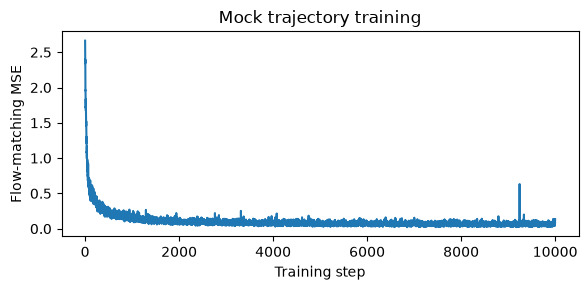

In [33]:
optimizer = torch.optim.Adam(flow.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
n_training_steps = 10000
batch_size = 128
loss_history = []

flow.train()
for step in range(n_training_steps):
    indices = torch.randint(N_TRAIN, (batch_size,), device=device)
    target = target_paths[indices]
    condition = conditions[indices]
    noise = sample_smooth_noise(batch_size, target.shape[1])
    flow_time = torch.rand(batch_size, 1, device=device)

    # Conditional flow-matching interpolation from smooth Gaussian paths to mock paths.
    noisy_path = (1 - flow_time.unsqueeze(-1)) * noise + flow_time.unsqueeze(-1) * target
    target_velocity = target - noise

    optimizer.zero_grad(set_to_none=True)
    predicted_velocity = flow(flow_time, condition, noisy_path)
    loss = loss_fn(predicted_velocity, target_velocity)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

    if (step + 1) % 300 == 0:
        print(f"Step {step + 1:4d}/{n_training_steps}, flow loss: {loss.item():.4f}")

plt.figure(figsize=(6, 3))
plt.plot(loss_history)
plt.xlabel("Training step")
plt.ylabel("Flow-matching MSE")
plt.title("Mock trajectory training")
plt.tight_layout()
plt.show()


In [34]:
# Estimate a Trajectory from A to B
# For inference, provide both complete boundary states: [x, y, theta, vx, vy].
# The model samples interior states and inserts the supplied endpoints unchanged.
# A fresh mock path below is only a functional sanity check, not real-data evaluation.


State order: [x, y, theta, vx, vy]
Start state A: [-1.1333911418914795, -0.8635191917419434, 2.982175350189209, -1.1058319807052612, 0.17779748141765594]
Goal state B:  [-3.04640531539917, -0.5090487003326416, 3.149655342102051, -0.9107226729393005, -0.00734303193166852]
Trajectory shape: (1, 40, 5)
RMSE by state [x, y, theta, vx, vy]: [0.0728294774889946, 0.06206980347633362, 0.042336199432611465, 0.04890581965446472, 0.03629932180047035]


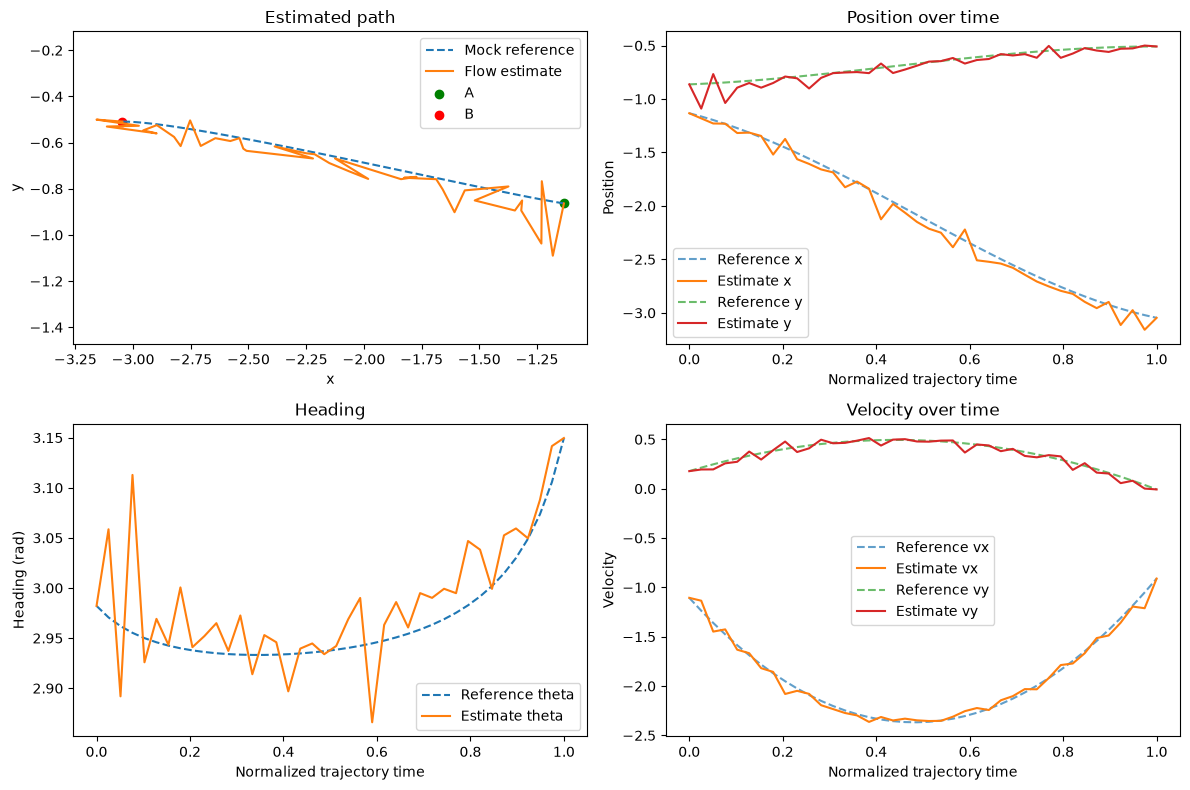

In [35]:
# Create a fresh mock A-to-B example for inference.
reference_path, state_a, state_b = make_mock_trajectories(1, N_STEPS)
condition_a = (state_a - state_mean.view(1, STATE_DIM)) / state_std.view(1, STATE_DIM)
condition_b = (state_b - state_mean.view(1, STATE_DIM)) / state_std.view(1, STATE_DIM)
inference_condition = torch.cat((condition_a, condition_b), dim=1)

# Flow-match a smooth random interior path into a trajectory conditioned on A and B.
generated_path = sample_smooth_noise(1, N_STEPS - 2)
n_flow_steps = 120
flow.eval()
with torch.no_grad():
    for index in range(n_flow_steps):
        t_start = index / n_flow_steps
        t_end = (index + 1) / n_flow_steps
        generated_path = flow.step(generated_path, inference_condition, t_start, t_end)

interior_states = generated_path * state_std + state_mean
estimated_path = torch.cat((state_a[:, None, :], interior_states, state_b[:, None, :]), dim=1)
state_rmse = (estimated_path - reference_path).square().mean(dim=(0, 1)).sqrt().cpu()
print("State order: [x, y, theta, vx, vy]")
print(f"Start state A: {state_a[0].cpu().tolist()}")
print(f"Goal state B:  {state_b[0].cpu().tolist()}")
print(f"Trajectory shape: {tuple(estimated_path.shape)}")
print(f"RMSE by state [x, y, theta, vx, vy]: {state_rmse.tolist()}")

reference = reference_path[0].cpu()
estimate = estimated_path[0].cpu()
time_axis = torch.linspace(0, 1, N_STEPS)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(reference[:, 0], reference[:, 1], "--", label="Mock reference")
axes[0, 0].plot(estimate[:, 0], estimate[:, 1], label="Flow estimate")
axes[0, 0].scatter([state_a[0, 0].item()], [state_a[0, 1].item()], c="green", label="A")
axes[0, 0].scatter([state_b[0, 0].item()], [state_b[0, 1].item()], c="red", label="B")
axes[0, 0].set(xlabel="x", ylabel="y", title="Estimated path")
axes[0, 0].axis("equal")
axes[0, 0].legend()

for state_index, label in ((0, "x"), (1, "y")):
    axes[0, 1].plot(time_axis, reference[:, state_index], "--", alpha=0.7, label=f"Reference {label}")
    axes[0, 1].plot(time_axis, estimate[:, state_index], label=f"Estimate {label}")
axes[0, 1].set(xlabel="Normalized trajectory time", ylabel="Position", title="Position over time")
axes[0, 1].legend()

axes[1, 0].plot(time_axis, reference[:, 2], "--", label="Reference theta")
axes[1, 0].plot(time_axis, estimate[:, 2], label="Estimate theta")
axes[1, 0].set(xlabel="Normalized trajectory time", ylabel="Heading (rad)", title="Heading")
axes[1, 0].legend()

for state_index, label in ((3, "vx"), (4, "vy")):
    axes[1, 1].plot(time_axis, reference[:, state_index], "--", alpha=0.7, label=f"Reference {label}")
    axes[1, 1].plot(time_axis, estimate[:, state_index], label=f"Estimate {label}")
axes[1, 1].set(xlabel="Normalized trajectory time", ylabel="Velocity", title="Velocity over time")
axes[1, 1].legend()

plt.tight_layout()
plt.show()
